# Phân đoạn u não cổ điển trên MRI bằng Otsu + Hậu xử lý

**Đồ án giữa kỳ — Xử lý ảnh số**

Xây dựng một pipeline **phân đoạn u não** thuần **cổ điển** (không dùng AI) trên
**LGG Segmentation Dataset** (Buda et al.). Phương pháp chính là **multi-Otsu +
hậu xử lý** (`otsu_postproc`); bản **Otsu thuần** (`otsu`) đóng vai trò **baseline
loại trừ (ablation)** để đo *từng bước thêm vào đóng góp bao nhiêu* vào độ chính
xác. Đánh giá định lượng bằng Dice/IoU so với mask ground-truth, phân tích giới hạn
và dẫn động lực sang phương pháp học sâu (U-Net) ở đồ án cuối kỳ.

> 🔖 *Bản nháp do Claude Code dựng — phần lý thuyết/biện luận cần (Người) rà soát & bổ sung trước khi nộp.*

In [1]:
# Thiết lập — notebook nằm trong notebooks/; chuyển cwd về thư mục gốc repo để src/ và đường dẫn dữ liệu (kaggle_3m/, figures/) hoạt động.
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
np.random.seed(0)

## 1. Đặt vấn đề

> 🔖 *Bản nháp do Claude Code dựng — phần lý thuyết/biện luận cần (Người) rà soát & bổ sung trước khi nộp.*

- **Bối cảnh lâm sàng:** glioma bậc thấp (LGG) là u thần kinh đệm; xác định chính
  xác ranh giới u trên ảnh MRI quan trọng cho chẩn đoán, theo dõi và **lập kế hoạch
  xạ trị**. Việc khoanh vùng thủ công tốn thời gian và phụ thuộc người đọc.
- **Tại sao khó:** u có **tương phản thấp** với mô lành, **kích thước thay đổi**
  lớn, ảnh MRI có **nhiễu Rician** và **bias field** (độ sáng không đều), ranh giới
  mờ → các phương pháp ngưỡng cổ điển dễ **over-/under-segmentation**.
- **Mục tiêu đồ án:** xây dựng một **pipeline phân đoạn u não cổ điển** (multi-Otsu + hậu xử lý), đánh giá định lượng bằng Dice/IoU, và **chứng minh giá trị của từng bước xử lý** bằng cách so với baseline Otsu thuần (nghiên cứu loại trừ — ablation), từ đó làm rõ *vì sao* cần phương pháp học sâu cho bài toán này.

## 2. Cơ sở lý thuyết

> 🔖 *Bản nháp do Claude Code dựng — phần lý thuyết/biện luận cần (Người) rà soát & bổ sung trước khi nộp.* *(Tham khảo: Gonzalez & Woods, Digital Image Processing, Ch. 3, 9 & 10.)*

**Lọc trung vị (median filter).** Bộ lọc thống kê thứ tự: thay mỗi điểm ảnh bằng
trung vị của lân cận (cửa sổ 5×5). Khử nhiễu muối tiêu hiệu quả mà **giữ biên** tốt
hơn lọc trung bình. Đây là bước tiền xử lý dùng chung cho cả hai phương pháp.

**Ngưỡng Otsu & multi-Otsu.** Otsu (1979) chọn ngưỡng tối đa hóa **phương sai
giữa các lớp** của histogram. Bản 2 lớp tách "sáng/tối"; **multi-Otsu 3 lớp** tách
histogram FLAIR thành *nền / mô não / u* và lấy lớp sáng nhất — khu trú u tốt hơn
ngưỡng 2 lớp (vốn chỉ tách được não khỏi nền).

**Hậu xử lý (hình thái học + giữ thành phần lớn nhất).** Trên mask nhị phân:
**opening** (co rồi giãn) khử các đốm sáng nhỏ/nhiễu; **closing** (giãn rồi co) lấp
lỗ trong vùng đặc. Kết hợp thêm bước **giữ thành phần liên thông lớn nhất** loại các
vùng sáng rời nằm ngoài u (chất xám, mắt/xoang) — nền tảng của phương pháp
`otsu_postproc`.

**Độ đo đánh giá.** Với mask dự đoán $P$ và ground-truth $G$:

$$\mathrm{Dice} = \frac{2|P\cap G|}{|P|+|G|}, \qquad \mathrm{IoU} = \frac{|P\cap G|}{|P\cup G|}.$$

Cả hai ∈ [0,1], càng cao càng khớp. Đây là độ đo **overlap** chuẩn cho
segmentation (không dùng PSNR/SSIM vốn cho phục hồi ảnh).

## 3. Phương pháp

### 3.1. Dữ liệu

LGG Segmentation Dataset: 110 bệnh nhân, ảnh `.tif` 3 kênh
(pre-contrast / **FLAIR** / post-contrast) kèm **mask FLAIR-abnormality** nhị phân.
`src/dataset.py` đọc cặp (ảnh, mask) và nhị phân hóa mask về {0,1}
(foreground = u = 1).

Tổng số cặp ảnh/mask: 3929


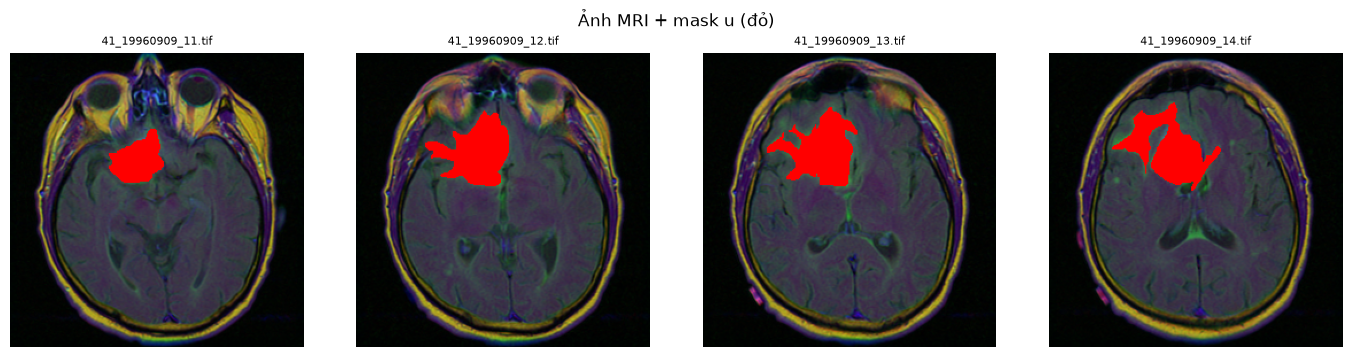

In [2]:
from src.dataset import find_pairs, load_dataset

pairs = find_pairs()
print(f"Tổng số cặp ảnh/mask: {len(pairs)}")

# Hiển thị overlay vài ca có u để xác nhận dữ liệu
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, s in zip(axes, load_dataset(limit=4, tumour_only=True)):
    ov = s.image.copy(); ov[s.mask == 1] = (255, 0, 0)
    ax.imshow(ov); ax.set_title(s.image_path.name[-18:], fontsize=8); ax.axis("off")
fig.suptitle("Ảnh MRI + mask u (đỏ)"); plt.tight_layout(); plt.show()

### 3.2. Tiền xử lý & lựa chọn kênh FLAIR

**Quyết định thiết kế:** dùng riêng **kênh FLAIR** thay vì gộp 3 kênh thành ảnh
xám. Lý do định lượng: trên các lát có u, độ tương phản *u − nền* ở FLAIR cao hơn
hẳn hai kênh kia → u nổi rõ hơn, công bằng vì mask ground-truth cũng là
FLAIR-abnormality. Mọi phương pháp đều dùng FLAIR + median 5×5.

In [3]:
from src.preprocessing import to_intensity, median_filter

names = ["pre-contrast", "FLAIR", "post-contrast"]
diffs = {n: [] for n in names}
for s in load_dataset(limit=30, tumour_only=True):
    img, m = s.image.astype(float), s.mask.astype(bool)
    for i, n in enumerate(names):
        ch = img[..., i]
        diffs[n].append(ch[m].mean() - ch[(~m) & (ch > 10)].mean())
print("Độ tương phản trung bình (u - nền) theo kênh (30 ca):")
for n in names:
    print(f"  {n:15s}: {np.mean(diffs[n]):+6.1f}")

Độ tương phản trung bình (u - nền) theo kênh (30 ca):
  pre-contrast   :   -9.3
  FLAIR          :  +47.4
  post-contrast  :   -2.3


### 3.3. Pipeline chính & baseline ablation

Cả hai cấu hình cài sau interface chung `segment(image) -> binary_mask` trong
`src/methods.py` (registry `METHODS`), dùng chung tiền xử lý FLAIR + median 5×5 —
**chỉ khác bước hậu xử lý**, nên đây là một thiết kế **loại trừ (ablation)** chứ
không phải hai đối thủ ngang hàng:

1. **`otsu` — baseline (ablation).** multi-Otsu 3 lớp, lấy lớp sáng nhất; **bỏ**
   bước hậu xử lý. Dùng để đo phần đóng góp của hậu xử lý.
2. **`otsu_postproc` — phương pháp chính.** multi-Otsu + opening/closing + giữ thành
   phần liên thông lớn nhất (loại mô sáng lạc: chất xám, mắt/xoang).

So sánh hai cấu hình trả lời câu hỏi *"bước hậu xử lý (morphology + keep-largest)
đóng góp bao nhiêu vào Dice?"* — chứ không phải *"phương pháp nào thắng?"*.

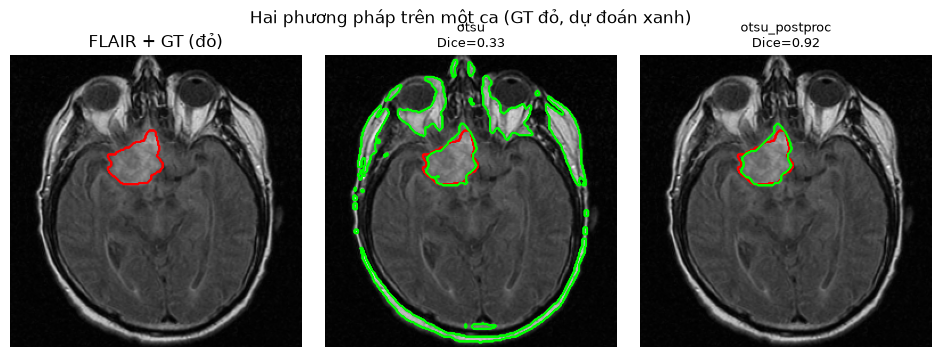

In [4]:
from src.methods import METHODS
from src.metrics import dice, iou

s = next(load_dataset(limit=1, tumour_only=True))
ncol = 1 + len(METHODS)
fig, axes = plt.subplots(1, ncol, figsize=(3.2 * ncol, 3.6))
flair = to_intensity(s.image, "flair")
axes[0].imshow(flair, cmap="gray"); axes[0].set_title("FLAIR + GT (đỏ)")
axes[0].contour(s.mask, colors="r", linewidths=0.8); axes[0].axis("off")
for ax, (name, fn) in zip(axes[1:], METHODS.items()):
    pred = fn(s.image)
    ax.imshow(flair, cmap="gray"); ax.contour(s.mask, colors="r", linewidths=0.8)
    ax.contour(pred, colors="lime", linewidths=0.8)
    ax.set_title(f"{name}\nDice={dice(pred, s.mask):.2f}", fontsize=9); ax.axis("off")
fig.suptitle("Hai phương pháp trên một ca (GT đỏ, dự đoán xanh)")
plt.tight_layout(); plt.show()

## 4. Thực nghiệm & đánh giá

Benchmark trên **toàn bộ bệnh nhân có u** (110 ca, mỗi bệnh nhân 1 lát giữa để tránh
thiên lệch), input FLAIR, cố định mọi tham số. `src/benchmark.py` chạy cả hai phương
pháp, tính Dice/IoU.

In [5]:
from src.benchmark import run_benchmark, summarise

df = run_benchmark(110)
summary = summarise(df)
summary

,dice_mean,dice_std,iou_mean,iou_std
method,,,,
otsu_postproc,0.418,0.417,0.363,0.379
otsu,0.349,0.278,0.248,0.222


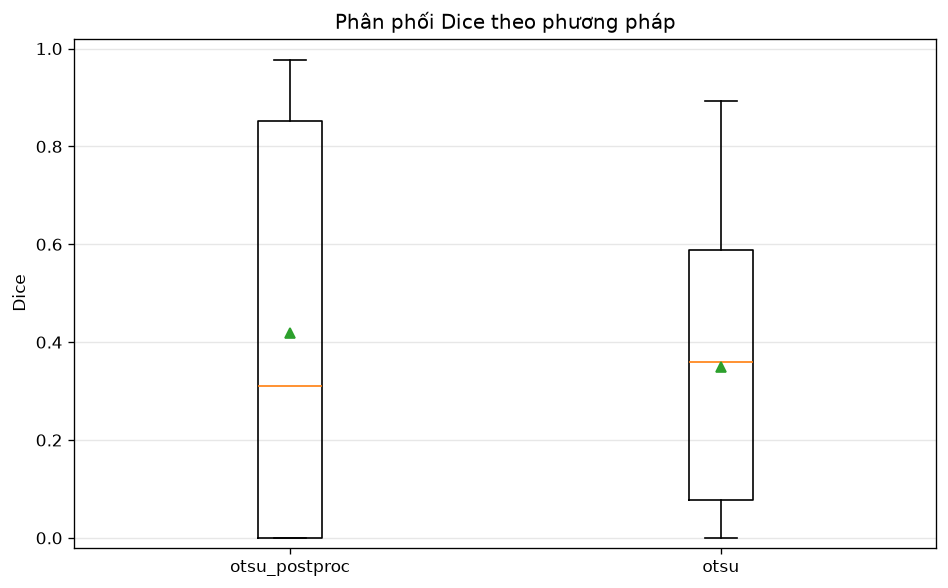

In [6]:
from src.benchmark import (select_samples, plot_boxplot, plot_qualitative,
                           plot_best_cases)
from pathlib import Path

FIG = Path("figures")
pairs = select_samples(110)
plot_boxplot(df, FIG / "phase4_dice_boxplot.png")
plot_qualitative(pairs, FIG / "phase4_qualitative.png")
plot_best_cases(df, pairs, FIG / "phase4_best_cases.png")
display(Image(str(FIG / "phase4_dice_boxplot.png")))

**Hình định tính** — 4 ca trải theo kích thước u (viền GT xanh, dự đoán đỏ):

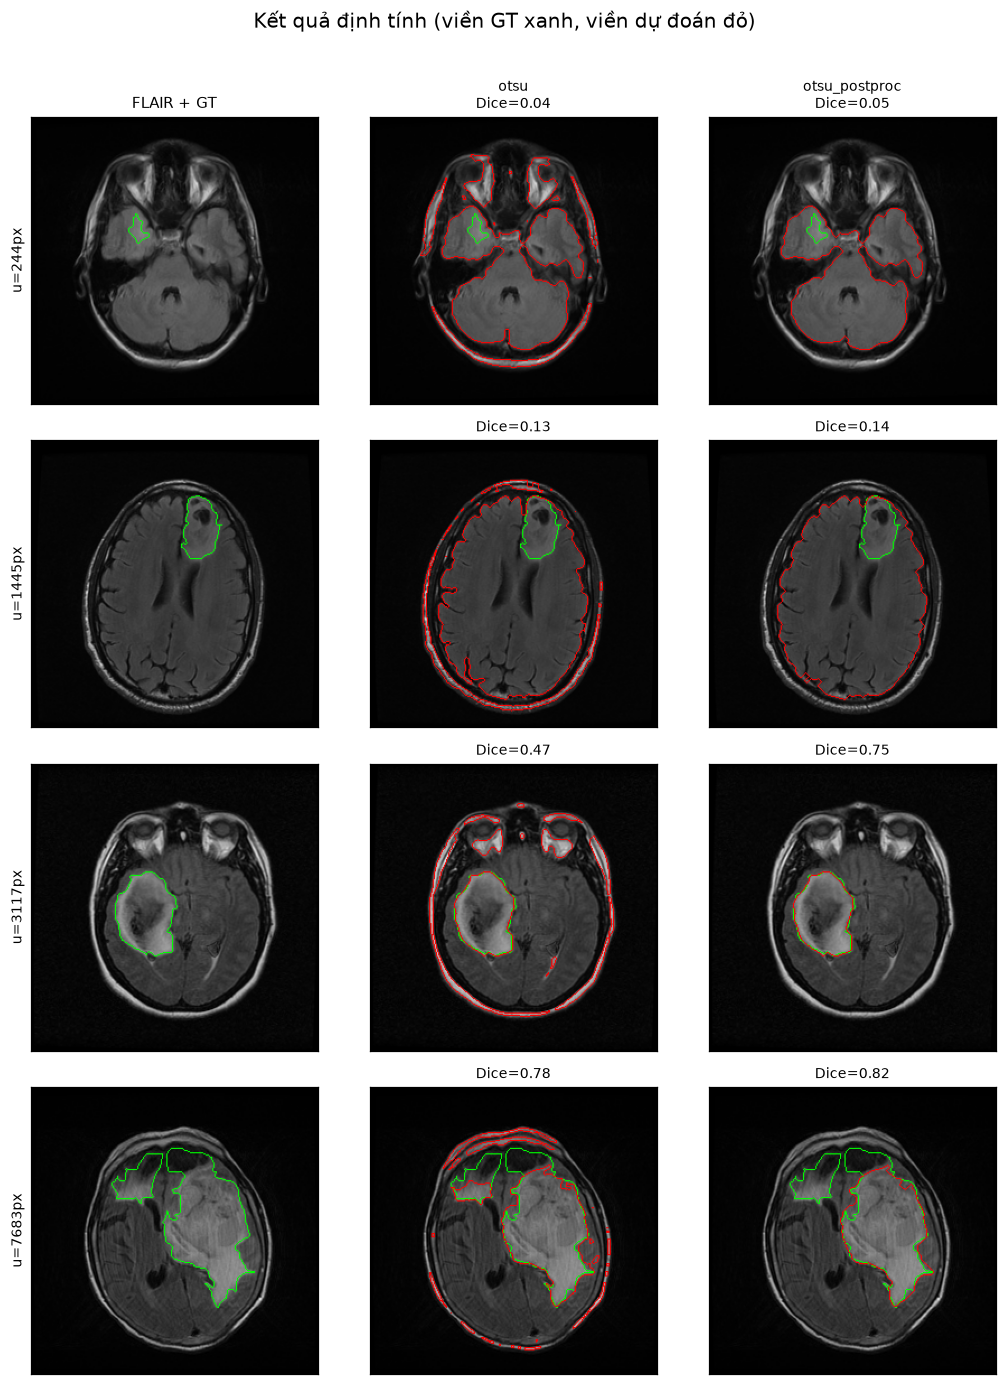

In [7]:
display(Image(str(FIG / "phase4_qualitative.png")))

**Ca tốt nhất mỗi phương pháp** — giới hạn trên của classical khi u to, sáng rõ:

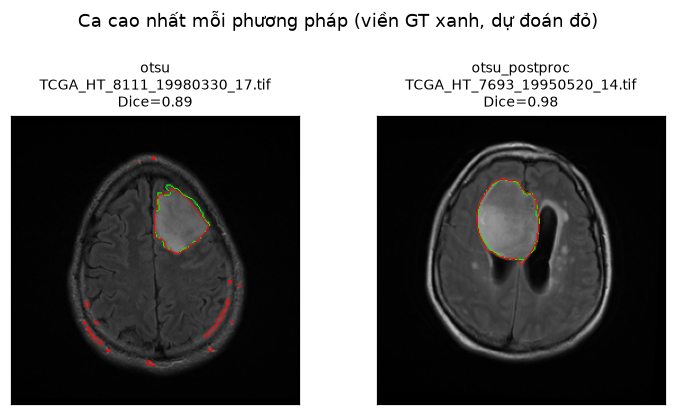

In [8]:
display(Image(str(FIG / "phase4_best_cases.png")))

### Nhận xét kết quả

> 🔖 *Bản nháp do Claude Code dựng — phần lý thuyết/biện luận cần (Người) rà soát & bổ sung trước khi nộp.*

- **Phương pháp chính `otsu_postproc`** đạt Dice trung bình ~0.42 và IoU cao hơn, nhờ
  bước opening/closing + giữ thành phần liên thông lớn nhất loại được mô sáng lạc.
- **Baseline `otsu`** (bỏ hậu xử lý) thấp hơn (~0.33) vì nhặt cả vùng sáng ngoài
  u → **bước hậu xử lý đóng góp ~+0.10 Dice**, xác nhận giá trị của hậu xử lý.
- Tuy nhiên cả hai cấu hình **đều kém ổn định** (std lớn) — `otsu_postproc` thậm chí
  phương sai cao hơn vì khi chọn nhầm khối lớn nhất thì Dice rơi về 0. Đây là giới
  hạn cốt lõi của classical, là manh mối cho phần phân tích giới hạn.

### So sánh với các công bố liên quan

Hai công bố dùng **ngưỡng Otsu cổ điển** trên MRI u não, gần với pipeline của đồ án:

- **Nyo et al. (2022) [5]** — gần như *đúng* pipeline của ta: tiền xử lý median filter →
  **multi-Otsu nhiều lớp (2/3/4)** → **morphology**, đánh giá bằng **Jaccard (= IoU)**
  trên 110 ảnh FLAIR (BRATS 2015). Đây là đối chứng trực tiếp nhất.
- **Tripathi et al. (2021) [6]** — **OKM** (Otsu + K-means) trên FLAIR, báo cáo **Dice**
  theo từng loại mô u (BRATS18).

> ⚠️ *So sánh chỉ mang tính tham chiếu xu hướng:* các bài trên dùng **dataset khác**
> (BRATS, gồm cả u bậc cao to/rõ) trong khi ta dùng **LGG** (u bậc thấp, nhỏ/mờ → khó hơn),
> và mỗi bài báo một độ đo khác nhau (Jaccard vs Dice).

In [9]:
# Số của ta lấy trực tiếp từ bảng `summary` ở trên; số văn liệu là hằng trích từ ref/.
ours = summary[["dice_mean", "iou_mean"]].round(3)
rows = []
for m in summary.index:  # otsu, otsu_postproc
    rows.append({
        "Công trình": "Đồ án này (2026)", "Phương pháp": m,
        "Dataset": f"LGG kaggle_3m ({df.image.nunique()} lát có u)",
        "Dice": f"{ours.loc[m, 'dice_mean']:.3f}",
        "IoU / Jaccard": f"{ours.loc[m, 'iou_mean']:.3f}",
    })
rows += [
    {"Công trình": "Nyo et al. 2022 [5]", "Phương pháp": "multi-Otsu 3 lớp",
     "Dataset": "BRATS 2015 (110 ảnh FLAIR)", "Dice": "—", "IoU / Jaccard": "0.503"},
    {"Công trình": "Nyo et al. 2022 [5]", "Phương pháp": "multi-Otsu 4 lớp + morphology",
     "Dataset": "BRATS 2015 (110 ảnh FLAIR)", "Dice": "—", "IoU / Jaccard": "0.565"},
    {"Công trình": "Tripathi et al. 2021 [6]", "Phương pháp": "OKM (Otsu + K-means)",
     "Dataset": "BRATS18 (theo từng loại mô)", "Dice": "0.78–0.85", "IoU / Jaccard": "—"},
]
import pandas as pd
pd.DataFrame(rows)

,Công trình,Phương pháp,Dataset,Dice,IoU / Jaccard
0,Đồ án này (2026),otsu_postproc,LGG kaggle_3m (110 lát có u),0.418,0.363
1,Đồ án này (2026),otsu,LGG kaggle_3m (110 lát có u),0.349,0.248
2,Nyo et al. 2022 [5],multi-Otsu 3 lớp,BRATS 2015 (110 ảnh FLAIR),—,0.503
3,Nyo et al. 2022 [5],multi-Otsu 4 lớp + morphology,BRATS 2015 (110 ảnh FLAIR),—,0.565
4,Tripathi et al. 2021 [6],OKM (Otsu + K-means),BRATS18 (theo từng loại mô),0.78–0.85,—


**Nhận xét so sánh** > 🔖 *Bản nháp do Claude Code dựng — cần (Người) rà soát.*

- **Khớp về xu hướng.** Nyo et al. cũng thấy *càng nhiều lớp Otsu càng tốt* (Jaccard
  0.19 → 0.50 → 0.57 cho 2/3/4 lớp) và **morphology cải thiện kết quả** — đúng đúng với
  việc `otsu_postproc` của ta (IoU 0.36) vượt `otsu` thuần (IoU 0.23). Quyết định thiết kế
  của đồ án (multi-Otsu ≥3 lớp + hậu xử lý hình thái) do đó **có cơ sở trong văn liệu**.
- **Chênh lệch tuyệt đối giải thích được, không phải do sai pipeline.** IoU của ta
  (~0.36) thấp hơn Nyo (~0.57) chủ yếu vì: (a) **dataset khó hơn** — LGG là u bậc *thấp*,
  nhỏ và tương phản kém, còn BRATS gồm cả u bậc cao to/rõ; (b) họ **chọn lớp tốt nhất**
  (class-4) và báo trên tập riêng.
- **Cảnh báo độ đo (điểm phân tích).** Nyo báo *accuracy* class-4 tới **95.6%** nhưng đó là
  con số gây hiểu nhầm do mất cân bằng lớp (u chỉ vài % pixel); chính **Jaccard ≈ 0.57** của
  họ mới phản ánh đúng — và nó vẫn chỉ ở mức trung bình, củng cố nhận định **ngưỡng Otsu cổ
  điển có trần ~0.5–0.6 IoU**, dù trên dataset thuận lợi.
- **Hướng tới AI.** OKM lai thêm K-means đạt Dice ~0.8 nhưng vẫn tiền-AI và chỉ đo theo từng
  loại mô. Tổng hợp lại: ngưỡng cổ điển *không vượt được* khoảng IoU ~0.6 — đúng động lực
  chuyển sang U-Net ở đồ án cuối kỳ.

## 5. Phân tích giới hạn (cầu nối sang AI)

### 5.1. Các ca thất bại

Tự động chọn 3 ca Dice thấp nhất mỗi phương pháp (`plot_worst_cases`).

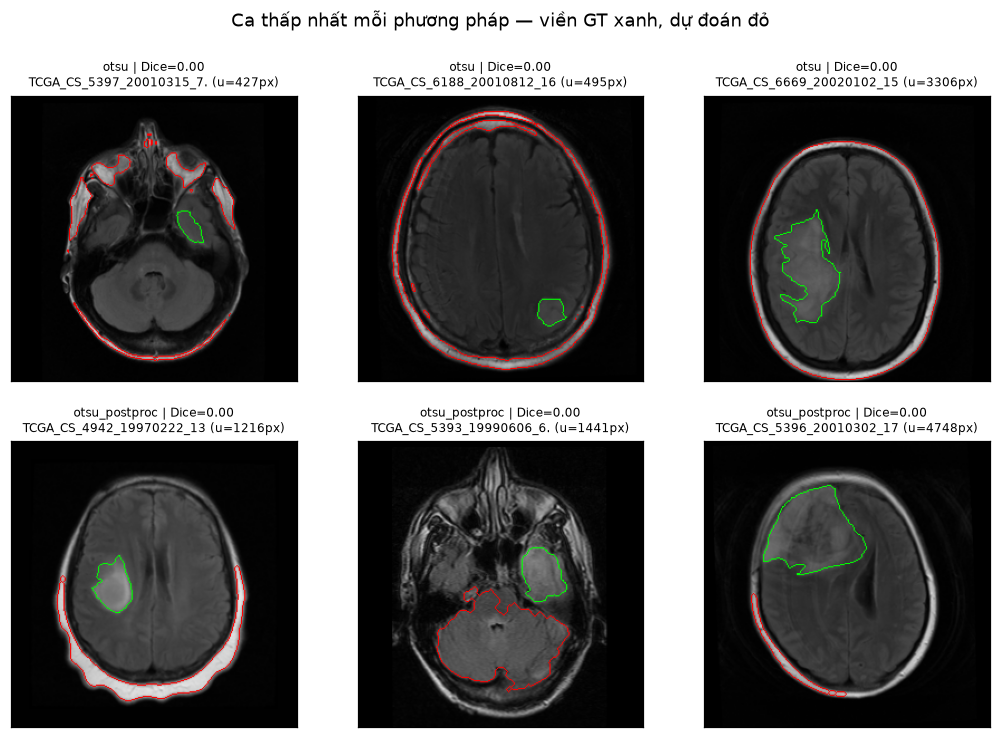

In [10]:
from src.benchmark import plot_worst_cases
plot_worst_cases(df, pairs, FIG / "phase5_worst_cases.png")
display(Image(str(FIG / "phase5_worst_cases.png")))

**Các kiểu thất bại quan sát được** > 🔖 *Bản nháp do Claude Code dựng — phần lý thuyết/biện luận cần (Người) rà soát & bổ sung trước khi nộp.*:
- **U nhỏ / tương phản thấp:** không tách được khỏi mô lành → mask rỗng hoặc lệch.
- **Lát nền sọ:** Otsu nhặt nhầm mắt/xoang sáng ngoài u.
- **Chọn nhầm thành phần lớn nhất:** `otsu_postproc` giữ một khối sáng không phải u → Dice 0.
- **Bias field:** độ sáng không đều khiến ngưỡng toàn cục cắt sai vùng u.

### 5.2. Độ nhạy tham số

Quét tham số `morph_iter` (số vòng opening/closing) của `otsu_postproc` (`src/sensitivity.py`).

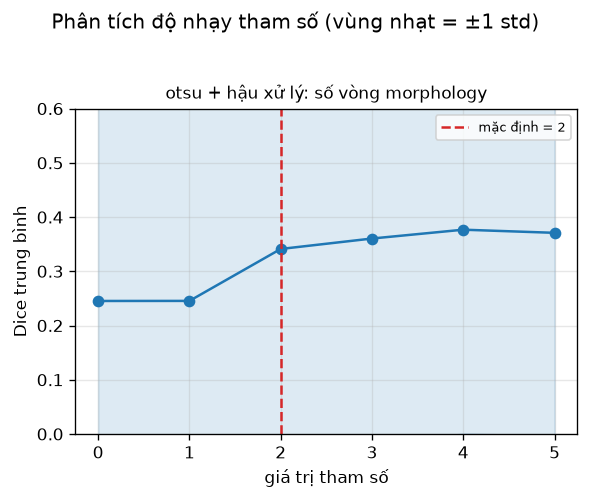

In [11]:
from src.sensitivity import run_sensitivity, plot_sensitivity
sens = run_sensitivity(30)
plot_sensitivity(sens, FIG / "phase5_sensitivity.png")
display(Image(str(FIG / "phase5_sensitivity.png")))

**Kết luận độ nhạy:** Dice của `otsu_postproc` thay đổi nhẹ theo số vòng morphology và
**bão hòa** sau một vài vòng (đường gần đơn điệu, không có đỉnh nhọn) → phương pháp
khá **bền** với tham số này; giá trị mặc định (2 vòng) nằm sát vùng tối ưu, không
cherry-pick.

## 6. Kết luận & hướng phát triển

> 🔖 *Bản nháp do Claude Code dựng — phần lý thuyết/biện luận cần (Người) rà soát & bổ sung trước khi nộp.*

- Các phương pháp cổ điển **khoanh được u khi điều kiện thuận lợi** (u to, sáng rõ:
  Dice tới ~0.9) nhưng **trung bình chỉ ~0.4 và rất không ổn định** trên toàn tập.
- Nguyên nhân gốc: chúng dựa thuần vào **cường độ/biên cục bộ**, không học được
  **đặc trưng hình thái & ngữ cảnh** của u → thất bại với u nhỏ, tương phản thấp,
  nhiễu, bias field.
- **Hướng phát triển:** mô hình học sâu **U-Net** học đặc trưng phân cấp từ dữ liệu,
  kỳ vọng ổn định hơn hẳn. Đồ án cuối kỳ sẽ huấn luyện U-Net **trên cùng dataset &
  cùng độ đo Dice/IoU** để so sánh trực tiếp với baseline classical ở đây.

### Tài liệu tham khảo
1. R. C. Gonzalez, R. E. Woods. *Digital Image Processing*, ch. 3 & 10.
2. N. Otsu (1979). *A threshold selection method from gray-level histograms.*
3. M. Buda, A. Saha, M. A. Mazurowski (2019). *Association of genomic subtypes of
   lower-grade gliomas... LGG Segmentation Dataset.* Computers in Biology and Medicine.
4. L. R. Dice (1945). *Measures of the amount of ecologic association between species.*
5. M. T. Nyo, F. Mebarek-Oudina, S. S. Hlaing, N. A. Khan (2022). *Otsu's thresholding technique for MRI image brain tumor segmentation.* Multimedia Tools and Applications, 81:43837–43849.
6. P. Tripathi, V. K. Singh, M. C. Trivedi (2021). *Brain tumor segmentation in magnetic resonance imaging using OKM approach.* Materials Today: Proceedings, 37:1334–1340.